# EDA — Phishing vs Legitimate URL (dataset_small)
**Mục tiêu:** chạy chuỗi phân tích **Tổng quan → Đơn biến → Hai biến → Đa biến** và *ghi nhận* các lỗi tiềm ẩn lộ ra. Notebook **không loại, không sửa** cột nào; toàn bộ 111 đặc trưng được giữ nguyên để đánh giá các thuật toán chọn đặc trưng. Mỗi lỗi có mã `L#`, tổng hợp ở mục 4.

## 0. Tổng quan

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200, "display.max_columns", 30)

DATA_PATH = "../data/raw/dataset_small.csv"   # <- sửa đường dẫn nếu cần
TARGET = "phishing"                           # 1 = phishing, 0 = legit
df = pd.read_csv(DATA_PATH)
X, y = df.drop(columns=TARGET), df[TARGET]

# Dataset không kèm dictionary -> chia nhóm cột theo hậu tố tên cột (_url, _domain, _directory, _file, _params) + nhóm tra cứu ngoài
EXT = ["time_response", "domain_spf", "asn_ip", "time_domain_activation", "time_domain_expiration", "qty_ip_resolved", "qty_nameservers",
       "qty_mx_servers", "ttl_hostname", "tls_ssl_certificate", "qty_redirects", "url_google_index", "domain_google_index", "url_shortened"]
SPECIAL = {"domain_length": "domain", "directory_length": "directory", "file_length": "file", "params_length": "params", "qty_params": "params",
           "domain_in_ip": "domain", "server_client_domain": "domain", "email_in_url": "url"}
def grp(c):
    if c in EXT: return "tra cứu ngoài"
    if c in SPECIAL: return SPECIAL[c]
    return next(s[1:] for s in ["_url", "_domain", "_directory", "_file", "_params"] if c.endswith(s))
GROUP = {c: grp(c) for c in X}

dup_feat = X.duplicated(keep=False)
g = df[dup_feat].groupby(list(X.columns))[TARGET].agg(["size", "nunique"])
display(pd.Series({
  "Số dòng × số đặc trưng": f"{len(df)} × {X.shape[1]}",
  "Kiểu dữ liệu": str(X.dtypes.astype(str).value_counts().to_dict()),
  "Ô NaN": int(df.isna().sum().sum()),
  "Nhãn (1 = phishing / 0 = legit)": str(y.value_counts().to_dict()),
  "Dòng trùng toàn bộ (gồm nhãn)": int(df.duplicated().sum()),
  "Dòng trùng đặc trưng": int(X.duplicated().sum()),
  "Số dòng thuộc nhóm trùng đặc trưng (theo nhãn)": f"{int(dup_feat.sum())} {y[dup_feat].value_counts().to_dict()}",
  "Nhóm trùng đặc trưng nhưng mâu thuẫn nhãn": f"{int((g['nunique'] > 1).sum())} nhóm ({int(g.loc[g['nunique'] > 1, 'size'].sum())} dòng)",
  "Số cột theo nhóm": str(pd.Series(GROUP).value_counts().to_dict()),
}, name="giá trị").to_frame())

,giá trị
Số dòng × số đặc trưng,58645 × 111
Kiểu dữ liệu,"{'int64': 110, 'float64': 1}"
Ô NaN,0
Nhãn (1 = phishing / 0 = legit),"{1: 30647, 0: 27998}"
Dòng trùng toàn bộ (gồm nhãn),1240
Dòng trùng đặc trưng,1246
Số dòng thuộc nhóm trùng đặc trưng (theo nhãn),"1664 {0: 1447, 1: 217}"
Nhóm trùng đặc trưng nhưng mâu thuẫn nhãn,6 nhóm (13 dòng)
Số cột theo nhóm,"{'domain': 21, 'url': 20, 'params': 20, 'direc..."


**Phát hiện**
- **L1** Dòng trùng: 1.240 dòng trùng toàn bộ, 1.246 dòng trùng đặc trưng. 1.664 dòng thuộc nhóm trùng, trong đó **87% là legit** (1.447 legit so với 217 phishing). 6 nhóm (13 dòng) có cùng đặc trưng nhưng khác nhãn.

## 1. Đơn biến
### 1.1. Phân loại cột theo các giá trị khác nhau

In [2]:
nu = X.nunique()
kind = pd.cut(nu, [0, 1, 2, 20, np.inf], labels=["hằng số (1)", "nhị phân (2)", "rời rạc (3–20)", "liên tục/đếm (>20)"])
for category, columns in kind.groupby(kind, observed=False):
    print(f"\n{category} ({len(columns)} cột):")
    print(", ".join(columns.index))


hằng số (1) (13 cột):
qty_slash_domain, qty_questionmark_domain, qty_equal_domain, qty_and_domain, qty_exclamation_domain, qty_space_domain, qty_tilde_domain, qty_comma_domain, qty_plus_domain, qty_asterisk_domain, qty_hashtag_domain, qty_dollar_domain, qty_percent_domain

nhị phân (2) (13 cột):
qty_at_domain, domain_in_ip, server_client_domain, qty_questionmark_directory, qty_hashtag_directory, qty_slash_file, qty_questionmark_file, qty_hashtag_file, qty_dollar_file, qty_hashtag_params, email_in_url, tls_ssl_certificate, url_shortened

rời rạc (3–20) (61 cột):
qty_questionmark_url, qty_equal_url, qty_at_url, qty_exclamation_url, qty_space_url, qty_tilde_url, qty_comma_url, qty_plus_url, qty_asterisk_url, qty_hashtag_url, qty_dollar_url, qty_tld_url, qty_dot_domain, qty_hyphen_domain, qty_underline_domain, qty_dot_directory, qty_underline_directory, qty_slash_directory, qty_equal_directory, qty_at_directory, qty_and_directory, qty_exclamation_directory, qty_space_directory, qty_tilde_

**Phát hiện**
- **L2** 13 cột hằng số (chỉ 1 giá trị), **toàn bộ thuộc nhóm `_domain`**: `qty_slash_domain`, `qty_questionmark_domain`, `qty_equal_domain`, `qty_and_domain`, `qty_exclamation_domain`, `qty_space_domain`, `qty_tilde_domain`, `qty_comma_domain`, `qty_plus_domain`, `qty_asterisk_domain`, `qty_hashtag_domain`, `qty_dollar_domain`, `qty_percent_domain`.

### 1.2 Biến nhị phân (13 cột)
Quy tắc `WARNING`: mã hóa khác {0,1} · lưu dạng float · có sentinel (-1) · gần hằng số (giá trị thiểu số < 1%).

In [3]:
SENT = [-1]   # dataset_small chỉ dùng -1 làm sentinel (không có giá trị âm nào khác, xem 1.5)

def show(t, mode="WARNING"):   # 3 mode: WARNING, OK, ALL. Mặc định WARNING. Muốn xem toàn bộ chỉ số thì đổi mode="ALL"
    print("Số cột theo status:", t["status"].value_counts().to_dict())
    if mode != "ALL": t = t[t["status"] == mode]
    paint = lambda v: "background-color: #c62828" if v == "WARNING" else "background-color: #1e8e3e"
    st = t.style.format(precision=1)
    (st.map if hasattr(st, "map") else st.applymap)(paint, subset=["status"])
    display(st)

b = nu[nu == 2].index
B = pd.DataFrame({"nhóm": pd.Series(GROUP)[b], "dtype": X[b].dtypes.astype(str),
                  "tập giá trị": [str(sorted(X[c].unique().tolist())) for c in b],
                  "đúng {0,1}": [set(X[c].unique()) == {0, 1} for c in b],
                  "%0": (X[b] == 0).mean()*100, "%1": (X[b] == 1).mean()*100, "%-1": (X[b] == -1).mean()*100})
B["%thiểu số"] = X[b].apply(lambda s: s.value_counts(normalize=True).iloc[-1])*100
B["số dòng thiểu số"] = (B["%thiểu số"]/100*len(X)).round().astype(int)

def why(r):
    o = []
    if not r["đúng {0,1}"]: o.append("mã hóa ≠ {0,1}")
    if not r["dtype"].startswith("int"): o.append("lưu float")
    if r["%-1"] > 0: o.append("có sentinel -1")
    if r["%thiểu số"] < 1: o.append("gần hằng số (<1%)")
    return "; ".join(o)

B["ghi chú"] = B.apply(why, axis=1); B["status"] = np.where(B["ghi chú"] == "", "OK", "WARNING")
show(B.sort_values("%thiểu số"))

# chứng minh: các cột {-1,0} chỉ là chỉ báo "URL không có phần này"
neg0 = [c for c in b if set(X[c].unique()) == {-1, 0}]
absent = {"directory": X.directory_length == -1, "file": X.directory_length == -1, "params": X.params_length == -1}
print(f"{len(neg0)} cột {{-1,0}} trùng khít chỉ báo 'thiếu phần này':", all((X[c] == -absent[GROUP[c]].astype(int)).all() for c in neg0))

Số cột theo status: {'WARNING': 11, 'OK': 2}


,nhóm,dtype,tập giá trị,"đúng {0,1}",%0,%1,%-1,%thiểu số,số dòng thiểu số,ghi chú,status
qty_at_domain,domain,int64,"[0, 1]",True,100.0,0.0,0.0,0.0,1,gần hằng số (<1%),WARNING
domain_in_ip,domain,int64,"[0, 1]",True,99.7,0.3,0.0,0.3,201,gần hằng số (<1%),WARNING
server_client_domain,domain,int64,"[0, 1]",True,99.6,0.4,0.0,0.4,207,gần hằng số (<1%),WARNING
url_shortened,tra cứu ngoài,int64,"[0, 1]",True,99.2,0.8,0.0,0.8,486,gần hằng số (<1%),WARNING
qty_hashtag_params,params,int64,"[-1, 0]",False,12.7,0.0,87.3,12.7,7422,"mã hóa ≠ {0,1}; có sentinel -1",WARNING
qty_hashtag_directory,directory,int64,"[-1, 0]",False,70.1,0.0,29.9,29.9,17507,"mã hóa ≠ {0,1}; có sentinel -1",WARNING
qty_questionmark_directory,directory,int64,"[-1, 0]",False,70.1,0.0,29.9,29.9,17507,"mã hóa ≠ {0,1}; có sentinel -1",WARNING
qty_hashtag_file,file,int64,"[-1, 0]",False,70.1,0.0,29.9,29.9,17507,"mã hóa ≠ {0,1}; có sentinel -1",WARNING
qty_questionmark_file,file,int64,"[-1, 0]",False,70.1,0.0,29.9,29.9,17507,"mã hóa ≠ {0,1}; có sentinel -1",WARNING
qty_slash_file,file,int64,"[-1, 0]",False,70.1,0.0,29.9,29.9,17507,"mã hóa ≠ {0,1}; có sentinel -1",WARNING


7 cột {-1,0} trùng khít chỉ báo 'thiếu phần này': True


**Phát hiện** (11/13 WARNING)
- **L3** 7 cột "nhị phân" thực chất mã hóa **{-1, 0}**: `qty_questionmark_directory`, `qty_hashtag_directory`, `qty_slash_file`, `qty_questionmark_file`, `qty_hashtag_file`, `qty_dollar_file`, `qty_hashtag_params`. Dòng cuối của cell in `True`: cả 7 cột **trùng khít** chỉ báo "URL không có phần này", chúng không phải đặc trưng đếm ký tự.
- **L4** 4 cột gần hằng số: `qty_at_domain` (chỉ 1 dòng khác), `domain_in_ip` (0,34%), `server_client_domain` (0,35%), `url_shortened` (0,83%).

### 1.3 Biến rời rạc (61 cột, 3–20 giá trị)
Quy tắc `WARNING`: có sentinel (-1) · có giá trị âm khác -1 · không phải số nguyên · giá trị chủ đạo ≥ 99% · nhóm tra cứu ngoài có ≥ 10% số 0.

In [4]:
ZERO_SENS = ["tra cứu ngoài"]   # nhóm mà số 0 có thể là "không có dữ liệu"
d = nu[(nu > 2) & (nu <= 20)].index
D = pd.DataFrame({"nhóm": pd.Series(GROUP)[d], "unique": nu[d],
                  "tập giá trị": [str(sorted(X[c].unique().tolist())) if nu[c] <= 4 else f"{X[c].min():g}–{X[c].max():g}" for c in d],
                  "%-1": (X[d] == -1).mean()*100, "%âm khác -1": (X[d] < -1).mean()*100, "%0": (X[d] == 0).mean()*100,
                  "chủ đạo": X[d].apply(lambda s: s.value_counts().index[0]), "%chủ đạo": X[d].apply(lambda s: s.value_counts(normalize=True).iloc[0])*100,
                  "số nguyên": [bool((X[c] % 1 == 0).all()) for c in d]})

def why(r):
    o = []
    if r["%-1"] > 0: o.append("có sentinel -1")
    if r["%âm khác -1"] > 0: o.append("có giá trị âm khác -1")
    if not r["số nguyên"]: o.append("không nguyên")
    if r["%chủ đạo"] >= 99: o.append("gần hằng số (≥99%)")
    if r["nhóm"] in ZERO_SENS and r["%0"] >= 10: o.append("nhiều số 0 (nghi thiếu)")
    return "; ".join(o)

D["ghi chú"] = D.apply(why, axis=1); D["status"] = np.where(D["ghi chú"] == "", "OK", "WARNING")
show(D.sort_values(["status", "%-1"], ascending=[False, False]))
print("Cột có sentinel -1 theo nhóm:", D[D["%-1"] > 0].groupby("nhóm").size().to_dict(), "| gần hằng số:", int(D["ghi chú"].str.contains("gần hằng số").sum()))

Số cột theo status: {'WARNING': 54, 'OK': 7}


,nhóm,unique,tập giá trị,%-1,%âm khác -1,%0,chủ đạo,%chủ đạo,số nguyên,ghi chú,status
qty_dot_params,params,18,-1–23,87.3,0.0,7.2,-1,87.3,True,có sentinel -1,WARNING
qty_underline_params,params,20,-1–21,87.3,0.0,8.8,-1,87.3,True,có sentinel -1,WARNING
qty_slash_params,params,17,-1–43,87.3,0.0,11.4,-1,87.3,True,có sentinel -1,WARNING
qty_questionmark_params,params,7,-1–9,87.3,0.0,11.5,-1,87.3,True,có sentinel -1,WARNING
qty_at_params,params,6,-1–10,87.3,0.0,10.0,-1,87.3,True,có sentinel -1,WARNING
qty_and_params,params,19,-1–22,87.3,0.0,6.6,-1,87.3,True,có sentinel -1,WARNING
qty_exclamation_params,params,6,-1–10,87.3,0.0,12.6,-1,87.3,True,có sentinel -1,WARNING
qty_space_params,params,4,"[-1, 0, 1, 4]",87.3,0.0,12.6,-1,87.3,True,có sentinel -1,WARNING
qty_tilde_params,params,3,"[-1, 0, 1]",87.3,0.0,12.6,-1,87.3,True,có sentinel -1,WARNING
qty_comma_params,params,8,-1–11,87.3,0.0,12.5,-1,87.3,True,có sentinel -1,WARNING


Cột có sentinel -1 theo nhóm: {'directory': 13, 'file': 11, 'params': 15, 'tra cứu ngoài': 5} | gần hằng số: 11


**Phát hiện** (54/61 WARNING)
- **L5** 44 cột rời rạc chứa sentinel -1: 15 cột `_params` (87,34% = -1), 13 cột `_directory` và 11 cột `_file` (29,85% = -1), 5 cột tra cứu (`domain_spf` 19,02%, `qty_redirects` 9,41%, `qty_ip_resolved` 6,22%, `url_google_index`, `domain_google_index`). Ở các cột `_params`, -1 còn là **giá trị chủ đạo**.
- **L6** 11 cột gần hằng số (≥ 99%): 8 cột `_url` (`qty_exclamation_url`, `qty_space_url`, `qty_tilde_url`, `qty_comma_url`, `qty_plus_url`, `qty_asterisk_url`, `qty_hashtag_url`, `qty_dollar_url`), `qty_underline_domain` (99,98%), `url_google_index` (99,86%), `domain_google_index` (99,77%).
- **L7** Nhóm tra cứu ngoài có nhiều số 0: `domain_spf` 65,0%, `qty_redirects` 60,3%, `qty_mx_servers` 20,3% → số 0 vừa có thể là "không có thật", vừa có thể là "tra cứu hỏng" (xem L15).
- Không có giá trị âm nào khác -1; cả 61 cột đều là số nguyên.

### 1.4 Biến liên tục (24 cột, > 20 giá trị)
Quy tắc `WARNING`: có sentinel (-1) · có giá trị âm khác -1 · nhóm tra cứu ngoài có ≥ 10% số 0 · |skew| ≥ 10 · đuôi cực đoan (max / P99 ≥ 10).

In [15]:
SHOW_HIST = False  # đặt False nếu không cần vẽ histogram
c = nu[nu > 20].index
q1, q3 = X[c].quantile(.25), X[c].quantile(.75); iqr = q3 - q1
C = pd.DataFrame({"nhóm": pd.Series(GROUP)[c], "min": X[c].min(), "P50": X[c].median(), "P99": X[c].quantile(.99), "max": X[c].max(),
                  "mean": X[c].mean(), "std": X[c].std(), "skew": X[c].skew(), "kurt": X[c].kurt(),
                  "%-1": (X[c] == -1).mean()*100, "%âm khác -1": (X[c] < -1).mean()*100, "%0": (X[c] == 0).mean()*100,
                  "%ngoại lai (3×IQR)": ((X[c] > q3 + 3*iqr) | (X[c] < q1 - 3*iqr)).mean()*100,
                  "số nguyên": [bool((X[k] % 1 == 0).all()) for k in c]})
C["max/P99"] = C["max"] / C["P99"].replace(0, np.nan)

def why(r):
    o = []
    if r["%-1"] > 0: o.append("có sentinel -1")
    if r["%âm khác -1"] > 0: o.append("có giá trị âm khác -1")
    if r["nhóm"] in ZERO_SENS and r["%0"] >= 10: o.append("nhiều số 0 (nghi thiếu)")
    if abs(r["skew"]) >= 10: o.append("lệch rất mạnh")
    if r["max/P99"] >= 10: o.append("đuôi cực đoan")
    return "; ".join(o)

C["ghi chú"] = C.apply(why, axis=1); C["status"] = np.where(C["ghi chú"] == "", "OK", "WARNING")
show(C.sort_values(["status", "skew"], ascending=[False, False]))
print("asn_ip: số giá trị duy nhất =", X.asn_ip.nunique(), "| top 4 giá trị:", X.asn_ip.value_counts().head(4).to_dict())
print("|skew| ≥ 1:", int((C["skew"].abs() >= 1).sum()), "/", len(C), "| |skew| ≥ 10:", int((C["skew"].abs() >= 10).sum()), "| max/P99 ≥ 10:", int((C["max/P99"] >= 10).sum()))

if SHOW_HIST:
    rep = ["length_url", "directory_length", "file_length", "params_length", "time_response", "time_domain_activation", "ttl_hostname", "asn_ip"]
    fig, ax = plt.subplots(2, 4, figsize=(14, 5))
    for a, k in zip(ax.ravel(), rep):
        v = X[k]; a.hist(v[v <= v.quantile(.99)], bins=40, color="#4C72B0"); a.set_title(f"{k}  (max={v.max():,.0f})", fontsize=9)
    plt.suptitle("Phân phối 8 cột đại diện (cắt ở P99, giữ nguyên giá trị -1)")
    plt.tight_layout()
    plt.show()

Số cột theo status: {'WARNING': 18, 'OK': 6}


,nhóm,min,P50,P99,max,mean,std,skew,kurt,%-1,%âm khác -1,%0,%ngoại lai (3×IQR),số nguyên,max/P99,ghi chú,status
qty_percent_file,file,-1.0,0.0,0.0,174.0,-0.2,1.7,54.6,4348.3,29.9,0.0,69.6,0.2,True,nan,có sentinel -1; lệch rất mạnh,WARNING
qty_percent_directory,directory,-1.0,0.0,1.0,174.0,-0.2,1.8,48.5,3498.6,29.9,0.0,68.7,0.4,True,174.0,có sentinel -1; lệch rất mạnh; đuôi cực đoan,WARNING
qty_percent_url,url,0.0,0.0,4.0,174.0,0.2,2.1,35.0,1996.8,0.0,0.0,97.4,2.6,True,43.5,lệch rất mạnh; đuôi cực đoan,WARNING
file_length,file,-1.0,0.0,45.0,1232.0,4.7,16.4,29.2,1474.5,29.9,0.0,33.5,1.4,True,27.4,có sentinel -1; lệch rất mạnh; đuôi cực đoan,WARNING
params_length,params,-1.0,-1.0,177.0,4094.0,8.5,42.6,22.0,1577.4,87.3,0.0,0.0,12.7,True,23.1,có sentinel -1; lệch rất mạnh; đuôi cực đoan,WARNING
qty_percent_params,params,-1.0,-1.0,1.0,65.0,-0.8,1.3,20.8,638.5,87.3,0.0,11.5,12.7,True,65.0,có sentinel -1; lệch rất mạnh; đuôi cực đoan,WARNING
qty_hyphen_params,params,-1.0,-1.0,1.0,35.0,-0.8,0.8,16.0,466.7,87.3,0.0,10.3,12.7,True,35.0,có sentinel -1; lệch rất mạnh; đuôi cực đoan,WARNING
length_url,url,4.0,29.0,253.0,4165.0,45.0,54.7,12.3,615.5,0.0,0.0,0.0,3.9,True,16.5,lệch rất mạnh; đuôi cực đoan,WARNING
qty_underline_url,url,0.0,0.0,3.0,21.0,0.2,0.8,10.4,165.9,0.0,0.0,91.0,9.0,True,7.0,lệch rất mạnh,WARNING
directory_length,directory,-1.0,7.0,104.0,1286.0,16.9,28.1,9.3,264.3,29.9,0.0,0.0,0.8,True,12.4,có sentinel -1; đuôi cực đoan,WARNING


asn_ip: số giá trị duy nhất = 2567 | top 4 giá trị: {-1: 4767, 13335: 4401, 15169: 4343, 20013: 2864}
|skew| ≥ 1: 23 / 24 | |skew| ≥ 10: 9 | max/P99 ≥ 10: 8


**Phát hiện** (18/24 WARNING)
- **L8** 15/24 cột liên tục có sentinel -1: `directory_length`, `file_length`, `params_length` (min = -1), các cột `qty_hyphen_*`, `qty_percent_*`, `qty_equal_params`, và nhóm tra cứu `time_domain_activation` (32,24%), `time_domain_expiration` (35,29%), `asn_ip` (8,13%), `time_response` (8,40%), `ttl_hostname` (6,22%). Vì -1 nằm cùng thang với giá trị thật nên mean/std bị méo (ví dụ `params_length` mean 8,5 trong khi 87% dòng là -1). Histogram có cột cao tại -1.
- **L9** 23/24 cột |skew| ≥ 1; 9 cột |skew| ≥ 10 (`qty_percent_file` 54,6; `qty_percent_directory` 48,5; `qty_percent_url` 35,0; `file_length` 29,2; `params_length` 22,0; ...); 8 cột có max ≥ 10×P99. Cực đoan: `length_url` max 4.165 so với P99 = 253.
- **L10** `asn_ip` có 2.567 giá trị duy nhất, lặp theo cụm: 13335 (4.401 dòng), 15169 (4.343), 20013 (2.864), -1 (4.767) → đây là **mã định danh hệ thống tự trị (ASN)** nhưng được lưu như số liên tục, thứ tự và độ lớn không có nghĩa. *(Suy luận từ domain knowledge, cần đối chiếu dictionary.)*

### 1.5. Sentinel -1 theo nhóm cột

In [6]:
neg1 = (X == -1).mean() * 100
display(pd.DataFrame({"số cột": pd.Series(GROUP).value_counts(),
                      "số cột có -1": (neg1 > 0).groupby(pd.Series(GROUP)).sum(),
                      "% -1 nhỏ nhất": neg1[neg1 > 0].groupby(pd.Series(GROUP)).min(),
                      "% -1 lớn nhất": neg1[neg1 > 0].groupby(pd.Series(GROUP)).max()}).fillna(0).round(2))
print(f"Tổng: {int((neg1 > 0).sum())}/{X.shape[1]} cột có -1 | số cột có giá trị âm khác -1: {int((X < -1).any().sum())}")

,số cột,số cột có -1,% -1 nhỏ nhất,% -1 lớn nhất
directory,18,18,29.85,29.85
domain,21,0,0.00,0.00
file,18,18,29.85,29.85
params,20,20,87.34,87.34
tra cứu ngoài,14,10,0.00,35.29
url,20,0,0.00,0.00


Tổng: 66/111 cột có -1 | số cột có giá trị âm khác -1: 0


**Phát hiện**
- **L11** **66/111 cột có -1** và không có giá trị âm nào khác. Nguồn rất rõ: `directory` 18/18 cột (29,85%), `file` 18/18 cột (29,85%), `params` 20/20 cột (87,34%), `tra cứu ngoài` 10/14 cột (tối đa 35,29%). Nhóm `url` và `domain` không có -1. Một mã hóa -1 dùng chung cho cả "URL không có phần này" lẫn "tra cứu thất bại".

## 2. Hai biến
### 2.1 Cột vs cột: kiểm tra cộng dồn (số liệu của cả URL = tổng các phần?)

In [7]:
Z = X.clip(lower=0)                                  # -1 (không có phần này) -> 0 khi cộng
chars = [k[4:-4] for k in X if k.startswith("qty_") and k.endswith("_url") and k != "qty_tld_url"]
rows = {}
for ch in chars + ["length"]:
    if ch == "length": u, parts = X.length_url, {k: Z[f"{k}_length"] for k in ["domain", "directory", "file", "params"]}
    else: u, parts = X[f"qty_{ch}_url"], {p: Z[f"qty_{ch}_{p}"] for p in ["domain", "directory", "file", "params"] if f"qty_{ch}_{p}" in X}
    A = parts["domain"] + parts["directory"] + parts["params"]       # không cộng file
    Bs = A + parts["file"]                                           # cộng cả file
    rows[ch] = {"url = dom+dir+par (%)": (u == A).mean()*100, "url = dom+dir+file+par (%)": (u == Bs).mean()*100}
t = pd.DataFrame(rows).T; t["chênh"] = t.iloc[:, 0] - t.iloc[:, 1]
display(t.sort_values("chênh", ascending=False).round(1))

,url = dom+dir+par (%),url = dom+dir+file+par (%),chênh
length,99.4,63.0,36.3
dot,99.7,75.6,24.1
hyphen,99.8,96.8,3.0
underline,99.9,97.8,2.1
percent,100.0,99.4,0.6
equal,99.7,99.5,0.2
exclamation,99.9,99.8,0.2
comma,100.0,100.0,0.0
and,99.7,99.7,0.0
plus,100.0,100.0,0.0


**Phát hiện**
- **L12** Các phần **không rời nhau**: `length_url = domain_length + directory_length + params_length` đúng 99,4% số dòng, trong khi cộng thêm `file_length` chỉ đúng 63,0%. Tương tự `qty_dot` (99,7% so với 75,6%), `qty_hyphen` (99,8% so với 96,8%), `qty_underline` (99,9% so với 97,8%). → `*_directory` đã **bao gồm cả phần file**, nên `*_file` là tập con của `*_directory` (dư thừa cấu trúc giữa hai nhóm cột).

### 2.2 Cột vs cột
**(a) Khối sentinel: -1 xuất hiện đồng loạt hay lẻ tẻ?**

In [8]:
blk = {"directory": [k for k in X if k.endswith("_directory")] + ["directory_length"],
       "file": [k for k in X if k.endswith("_file")] + ["file_length"],
       "params": [k for k in X if k.endswith("_params")] + ["params_length", "qty_params"]}
for k, cols in blk.items():
    m = (X[cols] == -1)
    print(f"[(a)] khối {k}: {len(cols)} cột | -1 đồng loạt: {int(m.all(axis=1).sum())} dòng | -1 lẻ (chỉ một phần): {int((m.any(axis=1) & ~m.all(axis=1)).sum())} dòng")
print("[(a)] directory = -1 ⇔ file = -1: số dòng lệch =", int(((X.directory_length == -1) != (X.file_length == -1)).sum()))

[(a)] khối directory: 18 cột | -1 đồng loạt: 17507 dòng | -1 lẻ (chỉ một phần): 0 dòng
[(a)] khối file: 18 cột | -1 đồng loạt: 17507 dòng | -1 lẻ (chỉ một phần): 0 dòng
[(a)] khối params: 21 cột | -1 đồng loạt: 51223 dòng | -1 lẻ (chỉ một phần): 0 dòng
[(a)] directory = -1 ⇔ file = -1: số dòng lệch = 0


**Phát hiện**
- **L13** Mỗi khối `directory` / `file` / `params` bị -1 **đồng loạt** (17.507 / 17.507 / 51.223 dòng), 0 dòng -1 lẻ; `directory = -1 ⇔ file = -1` lệch 0 dòng. Mỗi khối thực chất chỉ chứa **1 bit thông tin** (có/không có phần đó), phần còn lại là bản sao (cùng L3).

**(b) Các cột tra cứu: -1 có trùng nhau không?**

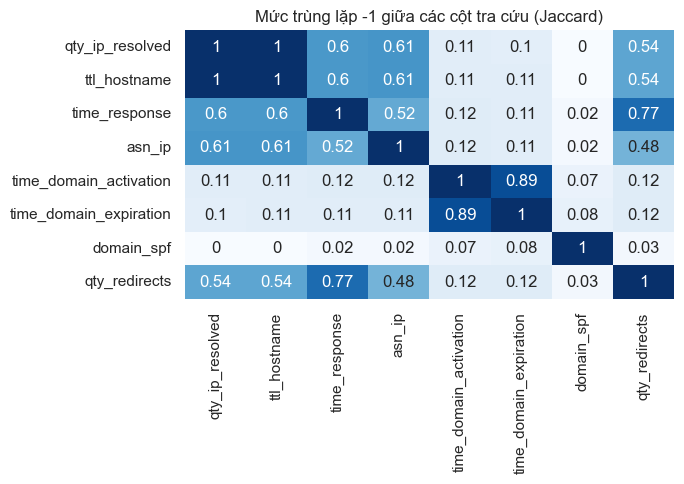

In [9]:
LK = ["qty_ip_resolved", "ttl_hostname", "time_response", "asn_ip", "time_domain_activation", "time_domain_expiration", "domain_spf", "qty_redirects"]
M = (X[LK] == -1).astype(int); inter = M.T.dot(M)
J = inter / (M.sum().values[:, None] + M.sum().values[None, :] - inter)
plt.figure(figsize=(7, 5)); sns.heatmap(J.round(2), annot=True, cmap="Blues", cbar=False)
plt.title("Mức trùng lặp -1 giữa các cột tra cứu (Jaccard)"); plt.tight_layout(); plt.show()

**Phát hiện**
- **L14** Sentinel của nhóm tra cứu chia thành **2 cụm**: cụm DNS/mạng (`qty_ip_resolved` ≡ `ttl_hostname` với Jaccard 1,00; `time_response`, `asn_ip`, `qty_redirects` cùng cụm, 0,48–0,77) và cụm WHOIS (`time_domain_activation`–`time_domain_expiration` 0,89). `domain_spf` độc lập với mọi cột khác (≤ 0,08).

**(c) Khi DNS lỗi (`qty_ip_resolved = -1`), các cột tra cứu khác nhận giá trị gì: -1 hay 0?**

In [10]:
fail = X.qty_ip_resolved == -1
cmp = {k: {"% -1 khi DNS lỗi": (X[k][fail] == -1).mean()*100, "% -1 khi DNS ổn": (X[k][~fail] == -1).mean()*100,
           "% 0 khi DNS lỗi": (X[k][fail] == 0).mean()*100, "% 0 khi DNS ổn": (X[k][~fail] == 0).mean()*100}
       for k in ["qty_nameservers", "qty_mx_servers", "domain_spf", "tls_ssl_certificate", "qty_redirects", "time_domain_activation", "url_google_index"]}
display(pd.DataFrame(cmp).T.round(1))

,% -1 khi DNS lỗi,% -1 khi DNS ổn,% 0 khi DNS lỗi,% 0 khi DNS ổn
qty_nameservers,0.0,0.0,5.9,0.0
qty_mx_servers,0.0,0.0,81.3,16.2
domain_spf,1.6,20.2,98.0,62.8
tls_ssl_certificate,0.0,0.0,96.4,46.8
qty_redirects,88.2,4.2,8.4,63.7
time_domain_activation,61.9,30.3,0.0,0.0
url_google_index,0.0,0.0,99.8,99.9


**Chú thích**
- `% -1 / % 0 khi DNS lỗi`: tỷ lệ dòng nhận giá trị -1 (hoặc 0) ở từng cột, trong nhóm dòng có `qty_ip_resolved = -1` (3.645 dòng).
- `% -1 / % 0 khi DNS ổn`: tỷ lệ tương ứng ở nhóm dòng còn lại.

**Phát hiện**
- **L15** Cùng một sự kiện "tra cứu thất bại" nhưng được mã hóa **không thống nhất**: `qty_redirects` nhận -1 (88,2% khi lỗi so với 4,2% khi ổn), trong khi `qty_mx_servers` nhận **0** (81,3% so với 16,2%), `tls_ssl_certificate` nhận 0 (96,4% so với 46,8%), `qty_nameservers` nhận 0 (5,9% so với 0,0%). Số 0 mang hai nghĩa ("không có thật" và "tra cứu hỏng") và không phân biệt được.

**(d) Bất biến logic giữa các cột** (quan hệ phải đúng nếu dữ liệu nhất quán)

In [11]:
part_len = {"domain": "domain_length", "directory": "directory_length", "file": "file_length", "params": "params_length", "url": "length_url"}
inv = {
 "qty_vowels_domain ≤ domain_length": X.qty_vowels_domain <= X.domain_length,
 "length_url ≥ domain_length": X.length_url >= X.domain_length,
 "directory_length ≥ file_length (khi có path)": (X.directory_length == -1) | (X.directory_length >= X.file_length),
 "file_length = 0 ⇒ mọi qty_*_file = 0": ~((X.file_length == 0) & (X[[k for k in X if k.startswith("qty_") and k.endswith("_file")]].gt(0).any(axis=1))),
 "qty_dot_domain ≥ 1": X.qty_dot_domain >= 1,
 "qty_tld_url ≥ 1 (trừ khi domain_in_ip = 1)": (X.qty_tld_url >= 1) | (X.domain_in_ip == 1),
 "domain_in_ip = 1 ⇒ qty_tld_url = 0": (X.domain_in_ip == 0) | (X.qty_tld_url == 0),
 "qty_equal_params > 0 ⇒ qty_params ≥ 1": (X.qty_equal_params <= 0) | (X.qty_params >= 1),
 "tld_present_params = -1 ⇔ params_length = -1": (X.tld_present_params == -1) == (X.params_length == -1),
 "qty_ip_resolved = -1 ⇔ ttl_hostname = -1": (X.qty_ip_resolved == -1) == (X.ttl_hostname == -1),
 "time_domain_activation = -1 ⇔ time_domain_expiration = -1": (X.time_domain_activation == -1) == (X.time_domain_expiration == -1),
}
for p, L in part_len.items():     # tổng các ký tự đặc biệt trong một phần không thể vượt độ dài phần đó
    qc = [k for k in X if k.startswith("qty_") and k.endswith("_" + p) and k != "qty_tld_url"]
    inv[f"Σ qty_*_{p} ≤ {L}"] = (X[L] < 0) | (X[qc].clip(lower=0).sum(axis=1) <= X[L])

status_df = pd.DataFrame({"số dòng vi phạm": [int((~v).sum()) for v in inv.values()],
                          "status": ["WARNING" if (~v).any() else "OK" for v in inv.values()]}, index=inv.keys())
ONLY_WARNING = True # Chỉ hiển thị các quy luật có WARNING, nếu muốn xem tất cả thì chỉnh lại thành False
n_rules = len(status_df)
if ONLY_WARNING:
    status_df = status_df[status_df["status"] == "WARNING"]

def style_status(val):
    color = "#c62828" if val == "WARNING" else "#1e8e3e"
    return f"color: white; background-color: {color}; text-align: center;"

if status_df.empty:
    print(f"Tất cả {n_rules} quy luật đều OK (không có WARNING nào).")
else:
    print(f"{len(status_df)}/{n_rules} quy luật có vi phạm")
    display(status_df.style.map(style_status, subset=["status"]))

7/16 quy luật có vi phạm


,số dòng vi phạm,status
qty_dot_domain ≥ 1,124,WARNING
qty_tld_url ≥ 1 (trừ khi domain_in_ip = 1),40,WARNING
domain_in_ip = 1 ⇒ qty_tld_url = 0,11,WARNING
qty_equal_params > 0 ⇒ qty_params ≥ 1,237,WARNING
qty_ip_resolved = -1 ⇔ ttl_hostname = -1,15,WARNING
time_domain_activation = -1 ⇔ time_domain_expiration = -1,2220,WARNING
Σ qty_*_params ≤ params_length,1,WARNING


**Phát hiện**
- **L16** 16 bất biến logic: 9 đạt 100% (gồm cả "tổng ký tự đặc biệt ≤ độ dài phần" cho domain/directory/file/url). 7 bất biến vi phạm:
  - `time_domain_activation = -1 ⇔ time_domain_expiration = -1`: **2.220 dòng** lệch (WHOIS chỉ trả về một nửa thông tin).
  - `qty_equal_params > 0 ⇒ qty_params ≥ 1`: **237 dòng** có dấu `=` trong params nhưng `qty_params = 0`.
  - `qty_dot_domain ≥ 1`: 124 dòng.
  - `qty_tld_url ≥ 1` (trừ URL dùng IP): 40 dòng.
  - `domain_in_ip = 1 ⇒ qty_tld_url = 0`: 11 dòng.
  - `qty_ip_resolved = -1 ⇔ ttl_hostname = -1`: 15 dòng.
  - `Σ qty_*_params ≤ params_length`: 1 dòng.

### 2.3 Cột vs nhãn: tỷ lệ giá trị -1 theo lớp

,số dòng,% legit,% phishing
params = -1 (không có tham số),51223.0,97.5,78.0
directory/file = -1 (không có path),17507.0,59.9,2.4
WHOIS activation = -1,18910.0,28.7,35.4
WHOIS expiration = -1,20698.0,33.6,36.8
DNS lỗi (qty_ip_resolved = -1),3645.0,9.6,3.1
SPF = -1,11153.0,15.2,22.5
redirects = -1,5519.0,14.2,5.1
time_response = -1,4925.0,12.6,4.5
asn_ip = -1,4767.0,11.5,5.1


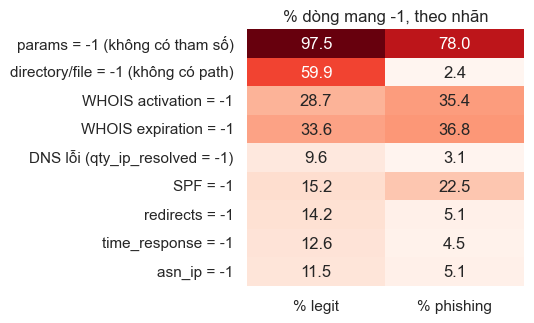

In [12]:
rules = {"params = -1 (không có tham số)": X.params_length == -1, "directory/file = -1 (không có path)": X.directory_length == -1,
         "WHOIS activation = -1": X.time_domain_activation == -1, "WHOIS expiration = -1": X.time_domain_expiration == -1,
         "DNS lỗi (qty_ip_resolved = -1)": X.qty_ip_resolved == -1, "SPF = -1": X.domain_spf == -1,
         "redirects = -1": X.qty_redirects == -1, "time_response = -1": X.time_response == -1, "asn_ip = -1": X.asn_ip == -1}
miss = pd.DataFrame({k: {"số dòng": int(m.sum()), "% legit": m[y == 0].mean()*100, "% phishing": m[y == 1].mean()*100} for k, m in rules.items()}).T
display(miss.round(1))
plt.figure(figsize=(5.5, 3.4)); sns.heatmap(miss[["% legit", "% phishing"]], annot=True, fmt=".1f", cmap="Reds", cbar=False)
plt.title("% dòng mang -1, theo nhãn"); plt.tight_layout(); plt.show()

**Phát hiện**
- **L17** Sentinel **lệch mạnh theo nhãn**: "không có path" chiếm 59,9% legit so với 2,4% phishing; "không có params" 97,5% so với 78,0%; `redirects = -1` 14,2% so với 5,1%; DNS lỗi 9,6% so với 3,1%. Chiều lệch không đồng nhất: `SPF = -1` và WHOIS = -1 lại phổ biến hơn ở phishing (22,5% so với 15,2%; 35,4% so với 28,7%). Việc "thiếu" tự nó mang thông tin nhãn.

## 3. Đa biến
### 3.1. Tương quan Spearman

In [13]:
Cm = X.loc[:, nu > 1].corr(method="spearman").abs()
p = Cm.where(np.triu(np.ones(Cm.shape, bool), 1)).stack().rename("|ρ|").reset_index().rename(columns={"level_0": "cột A", "level_1": "cột B"})
hi = p[p["|ρ|"] > 0.9].sort_values("|ρ|", ascending=False)
in_blk = lambda k: GROUP[k] in ("directory", "file", "params")     # 3 khối chịu ảnh hưởng của sentinel -1
both = hi.apply(lambda r: in_blk(r["cột A"]) and in_blk(r["cột B"]), axis=1)
print(f"Số cặp |ρ| > 0.9: {len(hi)} | cả 2 cột thuộc khối directory/file/params: {int(both.sum())} | còn lại: {int((~both).sum())} | |ρ| = 1.000: {int((hi['|ρ|'] > 0.9999).sum())}")
display(hi[~both].round(3).reset_index(drop=True))

Số cặp |ρ| > 0.9: 652 | cả 2 cột thuộc khối directory/file/params: 629 | còn lại: 23 | |ρ| = 1.000: 30


,cột A,cột B,|ρ|
0,qty_slash_url,qty_slash_directory,0.991
1,qty_at_url,email_in_url,0.974
2,qty_slash_url,directory_length,0.940
3,qty_equal_url,qty_equal_params,0.920
4,qty_equal_url,qty_params,0.919
5,qty_equal_url,qty_and_params,0.915
6,qty_equal_url,params_length,0.912
7,qty_equal_url,qty_underline_params,0.908
8,qty_equal_url,qty_questionmark_params,0.907
9,qty_equal_url,qty_dot_params,0.907


### 3.2 Tích lũy tín hiệu -1 trên mỗi dòng

In [14]:
nflag = sum(m.astype(int) for m in rules.values())
t = df.groupby(nflag)[TARGET].agg(["size", "mean"]).rename(columns={"size": "số dòng", "mean": "% phishing"}); t["% phishing"] *= 100
display(t.round(1).T)

,0,1,2,3,4,5,6,7,8,9
số dòng,3563.0,15905.0,15622.0,13599.0,5592.0,1441.0,938.0,681.0,1303.0,1.0
% phishing,86.8,67.7,41.9,54.9,31.3,37.8,21.0,39.6,1.0,0.0


**Phát hiện**
- **L18** 652 cặp |ρ| > 0,9, trong đó **629 cặp (96%) nằm trong 3 khối directory/file/params** và 30 cặp trùng hoàn toàn (|ρ| = 1,000), do các cột trong cùng khối cùng bị chi phối bởi một chỉ báo -1 (L3, L13). Trong 23 cặp còn lại, 20 cặp là `qty_equal_url` ↔ các cột `*_params` (|ρ| ≈ 0,91): đây cũng là hiệu ứng sentinel vì `qty_equal_url` đóng vai trò chỉ báo "có params". Chỉ 3 cặp là dư thừa thật: `qty_slash_url`–`qty_slash_directory` (0,991), `qty_at_url`–`email_in_url` (0,974), `qty_slash_url`–`directory_length` (0,940).
- **L19** Số tín hiệu -1 trên mỗi dòng liên quan mạnh đến nhãn nhưng **không đơn điệu**: 0 tín hiệu → 86,8% phishing; 1 → 67,7%; 2 → 41,9%; 3 → 54,9%; ≥ 8 tín hiệu (1.304 dòng) → khoảng 1%. Cấu trúc thiếu dữ liệu tự nó là một tín hiệu nhãn.

## 4. Tổng hợp lỗi phát hiện
*(Chỉ ghi nhận. Toàn bộ 111 cột được giữ nguyên.)*

| Nhóm lỗi | Mã | Cột liên quan | Bằng chứng chính |
|---|---|---|---|
| Dòng trùng | L1 | toàn bộ | 1.240 dòng trùng; 1.664 dòng thuộc nhóm trùng (87% legit); 6 nhóm mâu thuẫn nhãn |
| Hằng số / gần hằng số | L2, L4, L6 | 13 cột `_domain`; 4 nhị phân; 11 rời rạc | 1 giá trị duy nhất; thiểu số < 1%; chủ đạo ≥ 99% |
| Sentinel -1 | L5, L8, L11 | 66/111 cột (khối directory, file, params và 10 cột tra cứu) | -1 chiếm 6–87%, không có giá trị âm nào khác; mean/std bị méo |
| Mã hóa nhị phân sai | L3 | 7 cột {-1,0} | Trùng khít chỉ báo "thiếu phần URL" |
| Khối thông tin lặp | L12, L13 | `*_directory` ⊇ `*_file`; khối directory/file/params | url = dom+dir+par đúng 99,4% (cộng file: 63,0%); -1 đồng loạt, 0 dòng lẻ |
| Thiếu ẩn / mã hóa thiếu không thống nhất | L7, L14, L15 | `qty_mx_servers`, `tls_ssl_certificate`, `qty_nameservers`, `domain_spf`, `qty_redirects` | Khi DNS lỗi: -1 ở cột này, 0 ở cột khác (0 hai nghĩa); 2 cụm sentinel DNS và WHOIS |
| Định danh bị mã hóa số | L10 | `asn_ip` | 2.567 mã lặp theo cụm (13335, 15169, 20013) |
| Phân phối / ngoại lai | L9 | 23/24 cột liên tục | \|skew\| ≥ 1; 9 cột ≥ 10; `length_url` max 4.165 so với P99 = 253 |
| Bất nhất logic | L16 | `time_domain_*`, `qty_params`, `qty_dot_domain`, `qty_tld_url`, `domain_in_ip`, `ttl_hostname` | 7/16 bất biến vi phạm (tối đa 2.220 dòng) |
| Dư thừa / tương quan giả | L18 | 629/652 cặp trong khối sentinel; `qty_equal_url` ↔ `*_params` | 30 cặp \|ρ\| = 1,000; chỉ 3 cặp dư thừa thật |
| Liên quan nhãn | L17, L19 | các cột sentinel | Thiếu lệch mạnh theo nhãn, không đơn điệu (86,8% → ~1% phishing) |